<a href="https://colab.research.google.com/github/onyourbiya/Google_Colab/blob/main/penelitian_locket.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving locket_final.csv to locket_final.csv


In [2]:
import pandas as pd

df = pd.read_csv("locket_final.csv")

df.head()

,Tanggal,Rating,Review,Like,Clean_Review,Sentiment
0,2026-07-03 12:54:54,5,I love this app however I cant use the music f...,0,love app however cant use music filter someone...,Positive
1,2026-07-03 12:34:30,5,goood apps,0,goood apps,Positive
2,2026-07-03 07:00:28,5,lovveeeeed,0,lovveeeeed,Positive
3,2026-07-02 23:30:40,1,I'm getting so mad. every username is taken. c...,1,getting mad every username taken check delete ...,Negative
4,2026-07-02 21:42:58,5,"Great for communication with friends, very saf...",0,great communication friend safe fun google use...,Positive


In [3]:
print(df["Sentiment"].value_counts())

Sentiment
Positive    1128
Negative     413
Neutral      229
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

X = df["Clean_Review"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training :", len(X_train))
print("Jumlah data testing :", len(X_test))

Jumlah data training : 1416
Jumlah data testing : 354


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

ValueError: np.nan is an invalid document, expected byte or unicode string.

In [6]:
print(df.isnull().sum())

Tanggal          0
Rating           0
Review           0
Like             0
Clean_Review    10
Sentiment        0
dtype: int64


In [7]:
df = df.dropna(subset=["Clean_Review", "Sentiment"])

df = df[df["Clean_Review"].str.strip() != ""]

print(df.shape)
print(df.isnull().sum())

(1760, 6)
Tanggal         0
Rating          0
Review          0
Like            0
Clean_Review    0
Sentiment       0
dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

X = df["Clean_Review"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [10]:
# Menghapus data yang Clean_Review kosong
df = df.dropna(subset=["Clean_Review"])

# Menghapus string kosong
df = df[df["Clean_Review"].str.strip() != ""]

print(df.shape)
print(df.isnull().sum())

(1760, 6)
Tanggal         0
Rating          0
Review          0
Like            0
Clean_Review    0
Sentiment       0
dtype: int64


In [11]:
from sklearn.model_selection import train_test_split

X = df["Clean_Review"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(1408, 2247)
(352, 2247)


In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [14]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_tfidf)

print("Accuracy :", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy : 0.71875
              precision    recall  f1-score   support

    Negative       0.62      0.49      0.54        82
     Neutral       0.00      0.00      0.00        46
    Positive       0.76      0.95      0.84       224

    accuracy                           0.72       352
   macro avg       0.46      0.48      0.46       352
weighted avg       0.62      0.72      0.66       352



CONFUSSION MATRIX

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 40   5  37]
 [ 14   0  32]
 [ 11   0 213]]


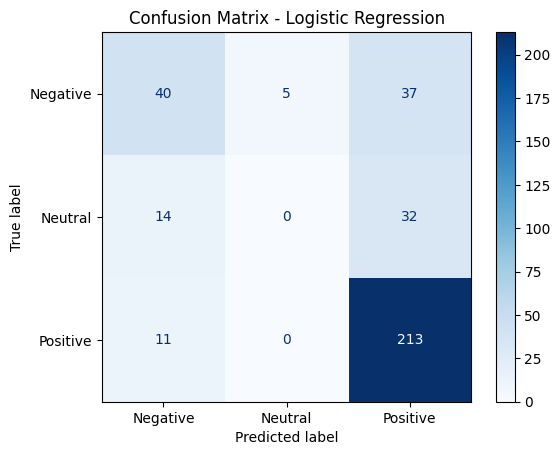

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

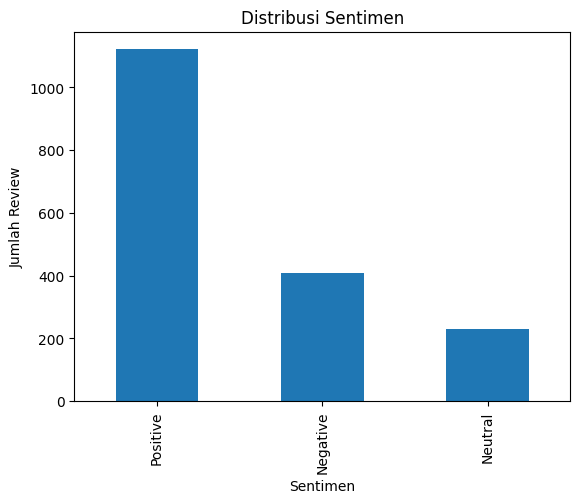

In [17]:
import matplotlib.pyplot as plt

df["Sentiment"].value_counts().plot(kind="bar")

plt.title("Distribusi Sentimen")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Review")

plt.show()

In [18]:
!pip install wordcloud

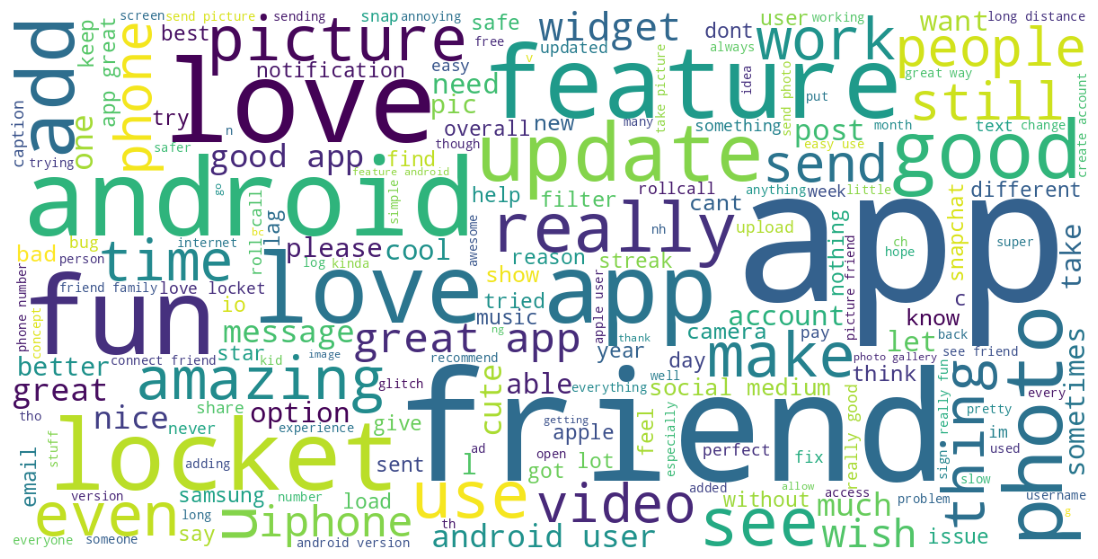

In [19]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(df["Clean_Review"])

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud)

plt.axis("off")

plt.show()

In [20]:
plt.savefig("confusion_matrix.png")

<Figure size 640x480 with 0 Axes>

LATIH SVM

In [21]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)

svm_model.fit(X_train_tfidf, y_train)

LinearSVC(random_state=42)

In [22]:
svm_pred = svm_model.predict(X_test_tfidf)

In [23]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy :", accuracy_score(y_test, svm_pred))

print(classification_report(y_test, svm_pred))

Accuracy : 0.7045454545454546
              precision    recall  f1-score   support

    Negative       0.54      0.54      0.54        82
     Neutral       0.33      0.15      0.21        46
    Positive       0.79      0.88      0.83       224

    accuracy                           0.70       352
   macro avg       0.55      0.52      0.53       352
weighted avg       0.67      0.70      0.68       352



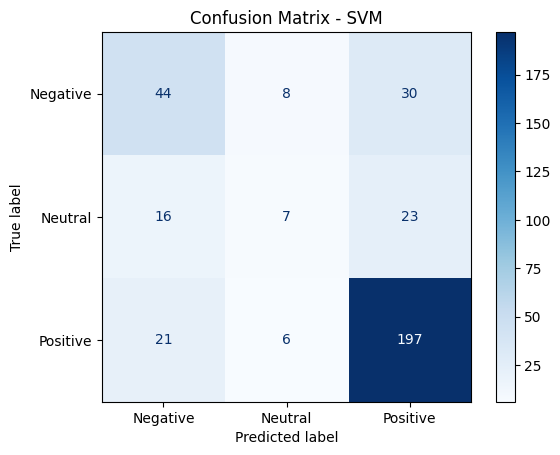

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=svm_model.classes_
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - SVM")

plt.show()

SMOTE

In [25]:
!pip install imbalanced-learn

In [26]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_train
)

print("Sebelum SMOTE:")
print(y_train.value_counts())

print("\nSesudah SMOTE:")
print(y_train_smote.value_counts())

Sebelum SMOTE:
Sentiment
Positive    898
Negative    327
Neutral     183
Name: count, dtype: int64

Sesudah SMOTE:
Sentiment
Positive    898
Negative    898
Neutral     898
Name: count, dtype: int64


LATIH ULANG SVM

In [27]:
from sklearn.svm import LinearSVC

svm_smote = LinearSVC(random_state=42)

svm_smote.fit(X_train_smote, y_train_smote)

LinearSVC(random_state=42)

In [28]:
#Prediksi
svm_smote_pred = svm_smote.predict(X_test_tfidf)

In [29]:
#Evaluasi
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy :", accuracy_score(y_test, svm_smote_pred))

print(classification_report(y_test, svm_smote_pred))

Accuracy : 0.6704545454545454
              precision    recall  f1-score   support

    Negative       0.46      0.48      0.47        82
     Neutral       0.30      0.30      0.30        46
    Positive       0.83      0.82      0.82       224

    accuracy                           0.67       352
   macro avg       0.53      0.53      0.53       352
weighted avg       0.67      0.67      0.67       352



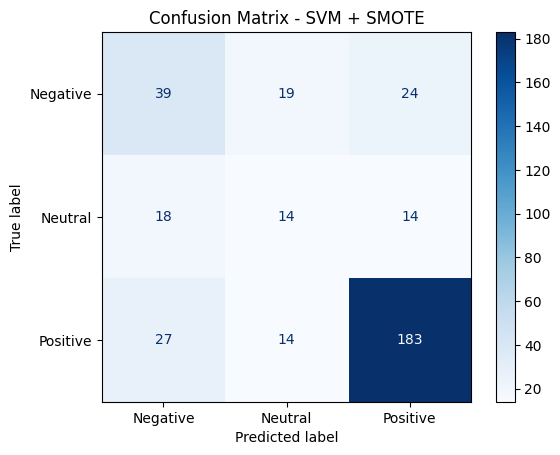

In [30]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, svm_smote_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_smote.classes_
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - SVM + SMOTE")
plt.show()

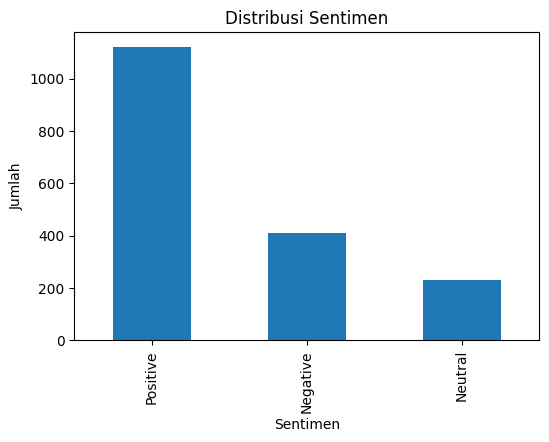

In [31]:
import matplotlib.pyplot as plt

sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(6,4))
sentiment_counts.plot(kind='bar')

plt.title("Distribusi Sentimen")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah")

plt.show()

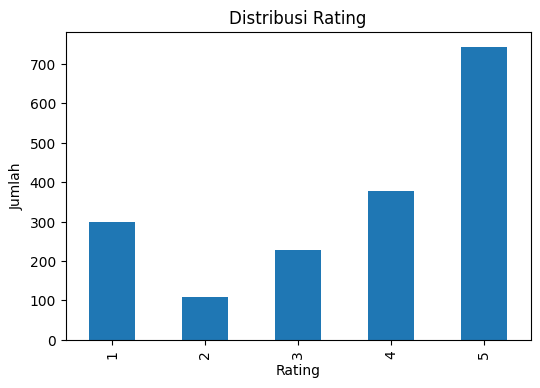

In [32]:
rating_counts = df['Rating'].value_counts().sort_index()

plt.figure(figsize=(6,4))
rating_counts.plot(kind='bar')

plt.title("Distribusi Rating")
plt.xlabel("Rating")
plt.ylabel("Jumlah")

plt.show()

In [33]:
!pip install wordcloud

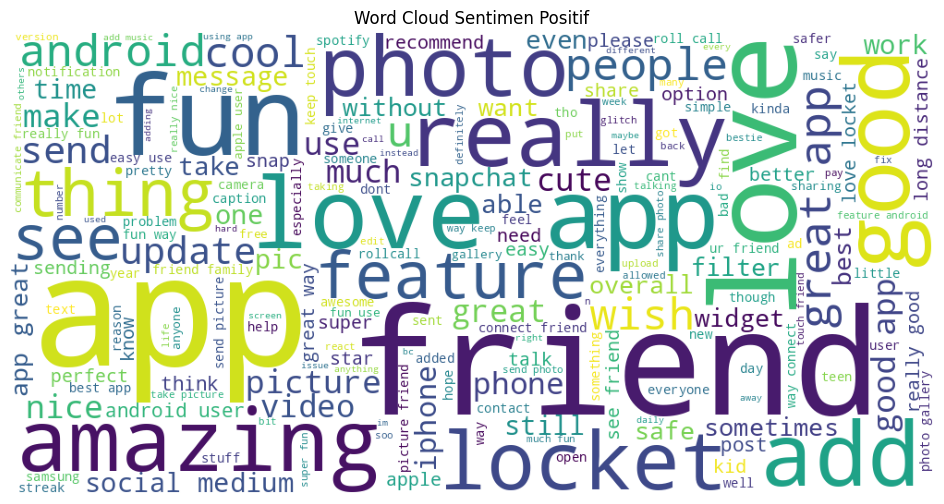

In [34]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(df[df['Sentiment']=="Positive"]['Clean_Review'])

wc = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wc)
plt.axis("off")
plt.title("Word Cloud Sentimen Positif")
plt.show()

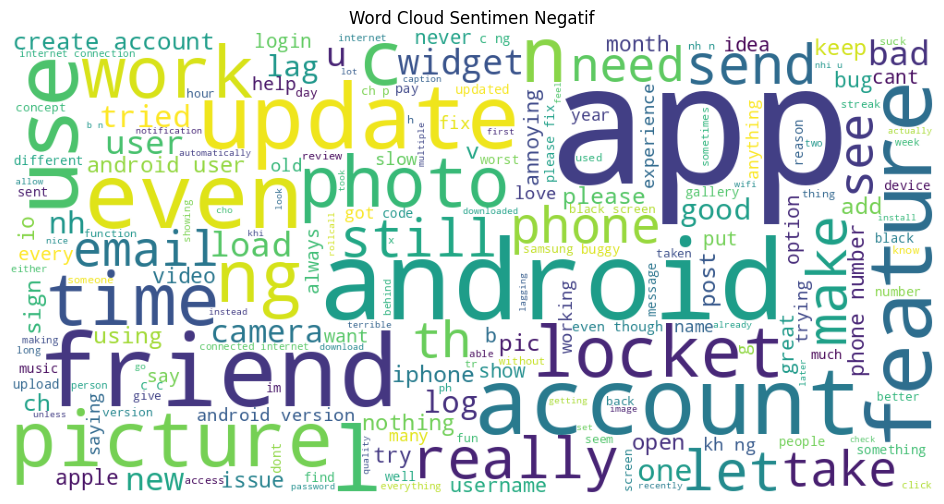

In [35]:
text = " ".join(df[df['Sentiment']=="Negative"]['Clean_Review'])

wc = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wc)
plt.axis("off")
plt.title("Word Cloud Sentimen Negatif")
plt.show()

In [36]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [37]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_train
)

In [38]:
from collections import Counter

print(Counter(y_train))
print(Counter(y_train_smote))

Counter({'Positive': 898, 'Negative': 327, 'Neutral': 183})
Counter({'Positive': 898, 'Negative': 898, 'Neutral': 898})


In [39]:
lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_smote.fit(
    X_train_smote,
    y_train_smote
)

LogisticRegression(max_iter=1000, random_state=42)

In [40]:
y_pred_lr_smote = lr_smote.predict(
    X_test_tfidf
)

In [41]:
print("Accuracy :", accuracy_score(y_test, y_pred_lr_smote))

print(classification_report(
    y_test,
    y_pred_lr_smote
))

Accuracy : 0.6789772727272727
              precision    recall  f1-score   support

    Negative       0.52      0.57      0.55        82
     Neutral       0.25      0.33      0.29        46
    Positive       0.87      0.79      0.83       224

    accuracy                           0.68       352
   macro avg       0.55      0.56      0.55       352
weighted avg       0.71      0.68      0.69       352



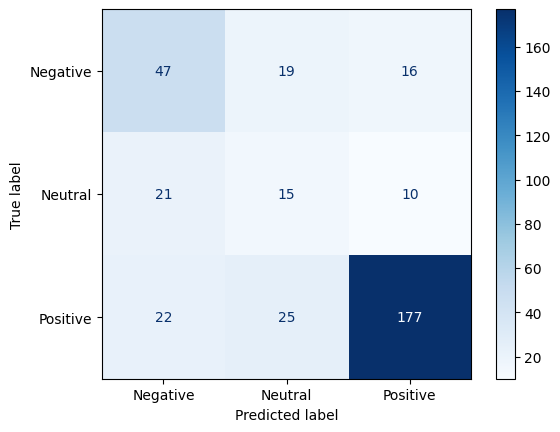

In [42]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr_smote,
    cmap="Blues"
)

plt.show()